# Merger simulation with a nested logit, version 2.0
**Project 1: VW–Fiat merger, course data `cars.csv`**

The notebook estimates (nested) logit demand for cars, recovers marginal costs from the pre-merger Bertrand–Nash equilibrium and simulates a merger between VW and Fiat. The notation follows the course note *Demand*.

**What changed from version 1**

- **Data:** the course's `cars.csv`, with the 40 best-selling cars in each of the 150 markets (6,000 rows).
- **Baseline specification**, chosen from the scenario grid in section 14:
  - one-level nested logit with **domestic vs. foreign** nests;
  - **market-year + brand** fixed effects;
  - all characteristics (log hp, weight, fuel use, speed, width, height, plus `home`);
  - **differentiation instruments** (Gandhi–Houde) at the market and nest level.
- **Configurable model:** the nest structure, fixed effects and instruments are settings in section 1. One-level and two-level trees and the simple logit all run through the same code.
- **New sections:**
  - diversion ratios between the VW and Fiat products (6);
  - break-even cost savings (13);
  - the scenario grid (14).

| Section | Content |
|---|---|
| 1 | Setup and parameters |
| 2 | Load data |
| 3 | Market shares and nests |
| 4 | Instruments and fixed effects |
| 5 | Demand estimation: 2SLS (5a) and GMM (5b) |
| 6 | The market model: shares, $\nabla s$, elasticities and diversion |
| 7 | Marginal costs from the pre-merger FOCs |
| 8 | Merger simulation |
| 9 | Results and welfare |
| 10 | The same merger in all five markets |
| 11 | Model comparison across nest structures |
| 12 | Own- and cross-price elasticity matrices |
| 13 | Break-even cost savings |
| 14 | Scenario grid: fixed effects × characteristics × instruments × nests |

**Notation**

| Note | Meaning | In the data / code |
|---|---|---|
| $t$, $j$, $f$ | market, product, firm | `ma` × `ye`, `co`, `frm` |
| $M_t$ | market size | `pop` / `DIVISOR` → `M` |
| $S_{jt}$, $s_{jt}(\cdot)$ | observed shares, model shares | `S`, `mk.shares(p)` |
| $\delta_{jt}$ | mean utility | `delta` |
| $g$, $h$ | nest and subnest | columns `g`, `hg` |
| $\rho_1$, $\rho_2$ | nesting parameters (subnest, nest); one level: $\rho_1 = \rho_2 = \rho$ | `theta2` |
| $\theta_1 = (\beta,\alpha)$, $\theta_2$ | linear and nonlinear parameters | |
| $H$, $H'$ | ownership matrix before / after the merger | `mk.ownership()` |
| $\nabla s$ | Jacobian $[\partial s_k/\partial p_j]$ | `mk.grad_s(p)` |
| $E_{jk}$, $D_{jk}$ | elasticity $\partial\log s_j/\partial\log p_k$, diversion ratio | |
| $c$, $\eta$, $\kappa$ | marginal cost, markup, efficiency $c'=c(1-\kappa)$ | `c`, `eta`, `KAPPA` |

**Price:** utility is $-\alpha \log p_{jt}$ with $p$ = `princ` (the note's default; `PRICE_SPEC = "levels"` gives $-\alpha p$). With market-year fixed effects, $\log$ `princ` and $\log$ `pr` give identical estimates.

## 1. Setup and parameters
All choices are made here. Re-run the whole notebook after changing them.

In [2]:
import numpy as np
import pandas as pd
from scipy.optimize import root, minimize, brentq
from scipy.special import logsumexp
from scipy.stats import chi2
from IPython.display import display, Markdown

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# --- Data and merger ---
DATA_PATH = "cars.csv"       # course data: 40 best-selling cars per market
LABELS_PATH = "cars.dta"     # only used for value labels (firm and market names)
MARKET, YEAR = 3, 98         # ma: 1 Belgium, 2 France, 3 Germany, 4 Italy, 5 UK; ye: 70-99
BUYER, SELLER = 26, 4        # frm codes: 26 = VW, 4 = Fiat
DIVISOR = 4.0                # market size M_t = pop / DIVISOR (households)
KAPPA = 0.0                  # merger efficiency: c' = c(1 - kappa) for the merging firms

# --- Demand specification ---
PRICE_SPEC = "log"           # "log": -alpha*log(p);  "levels": -alpha*p
NEST = "home"                # see NEST_OPTIONS below
FIXED_EFFECTS = ["mkt", "brd"]          # columns turned into dummies (mkt = market-year)
LOG_CHARS = ["hp", "we", "li", "sp", "wi", "he"]
CHARACTERISTICS = [f"log_{c}" for c in LOG_CHARS] + ["home"]
INSTRUMENTS = "gh"           # "gh", "gh_counts_xexr", "nest_sums", "counts" (section 4)
GH_CHARS = ["log_hp", "log_we", "log_li"]   # characteristics used for the differentiation IVs
ESTIMATOR = "2sls"           # "2sls" or "gmm" (two-step efficient GMM, section 5b)
CLUSTER = "co"               # cluster standard errors by model
RUN_GRID = False             # True re-runs the scenario grid in section 14 (about 8 minutes);
                             # False loads the saved results from scenario_grid_v2.csv

# Nest structures: (top nest, subnest). None = no nesting at that level.
NEST_OPTIONS = {
    "logit":          (None, None),     # simple logit
    "home":           ("home", None),   # one level: domestic vs. foreign
    "segment":        ("cla", None),    # one level: segment
    "segment_x_home": ("cla_home", None),  # one level: segment x domestic/foreign cells
    "segment>home":   ("cla", "home"),  # two levels: segment, then domestic/foreign
    "home>segment":   ("home", "cla"),  # two levels: domestic/foreign, then segment
}
NEST_LABELS = {"logit": "Simple logit", "home": "1 level: domestic/foreign",
               "segment": "1 level: segment", "segment_x_home": "1 level: segment × dom/for",
               "segment>home": "2 levels: segment → dom/for", "home>segment": "2 levels: dom/for → segment"}


def price_term(p):
    """f(p): how price enters mean utility."""
    return np.log(p) if PRICE_SPEC == "log" else p

def price_term_deriv(p):
    """f'(p), so that d delta_j / d p_j = -alpha * f'(p_j)."""
    return 1 / p if PRICE_SPEC == "log" else np.ones_like(p)

## 2. Load data
`cars.csv` is built from the raw data by the course's `materialize.ipynb`: it keeps the 40 best-selling cars in each market and merges in average income (`inc`). Value labels come from `cars.dta`. The firm labels are not unique (Toyota appears twice), so the codes are kept as numbers.

In [3]:
def load_data(path=DATA_PATH, labels_path=LABELS_PATH):
    df = pd.read_csv(path)
    df = df.astype({c: "float64" for c in df.select_dtypes("float32").columns})
    labels = pd.io.stata.StataReader(labels_path).value_labels()
    return df, labels

raw, labels = load_data()
assert raw.groupby(["ma", "ye"]).size().eq(40).all(), "expected 40 cars in every market"
firm_name = lambda f: labels.get("firm", {}).get(f, str(f))
market_name = lambda m: labels.get("market", {}).get(m, str(m))
print(f"{len(raw):,} rows, {raw.groupby(['ma','ye']).ngroups} markets, years 19{raw.ye.min()}-19{raw.ye.max()}")
print(f"Merger: {firm_name(BUYER)} acquires {firm_name(SELLER)}; main market {market_name(MARKET)} 19{YEAR}")

6,000 rows, 150 markets, years 1970-1999
Merger: VW acquires Fiat; main market Germany 1998


## 3. Market shares and nests
$S_{jt} = q_{jt}/M_t$ and $S_{0t} = 1-\sum_j S_{jt}$, with $M_t$ = `pop`/`DIVISOR`.

`nest_setup` adds the nest columns `g` (nest) and `hg` (subnest), and returns the log conditional shares that enter the estimating equation:

| Structure | `g` | `hg` | Terms in the regression |
|---|---|---|---|
| simple logit | one group | = `g` | none |
| one level | nest | = `g` | $\rho \log S_{j\mid g}$ |
| two levels | top nest | top × subnest | $\rho_1 \log S_{j\mid hg} + \rho_2 \log S_{h\mid g}$ |

The market class in section 6 handles all three, with $\rho_1 = \rho_2 = \rho$ for one level and $\rho = 0$ for the simple logit.

In [4]:
def build_shares(df, divisor=DIVISOR):
    df = df.copy()
    df["mkt"] = df["ma"].astype(int) * 1000 + df["ye"].astype(int)
    df["M"] = df["pop"] / divisor
    df["S"] = df["qu"] / df["M"]
    df["S0"] = 1 - df.groupby("mkt")["qu"].transform("sum") / df["M"]
    if (df["S0"] <= 0).any():
        raise ValueError("Outside share <= 0 in some market: lower DIVISOR.")
    df["y"] = np.log(df["S"]) - np.log(df["S0"])
    df["cla_home"] = df["cla"].astype(int) * 10 + df["home"].astype(int)
    df["sp"] = df["sp"].fillna(df.groupby(["mkt", "cla"])["sp"].transform("median"))
    for c in LOG_CHARS:
        df[f"log_{c}"] = np.log(df[c])
    return df


def nest_setup(df, nest=NEST):
    """Add nest columns g, hg and return the log conditional-share terms for this structure."""
    top, sub = NEST_OPTIONS[nest]
    d = df.copy()
    if top is None:                                   # simple logit
        d["g"] = 0
        d["hg"] = 0
        return d, {}
    d["g"] = d[top].astype(int)
    if sub is None:                                   # one level
        d["hg"] = d["g"]
        q_g = d.groupby(["mkt", "g"])["qu"].transform("sum")
        return d, {"log S_j|g": np.log(d["qu"] / q_g)}
    d["hg"] = d["g"] * 100 + d[sub].astype(int)       # two levels
    q_hg = d.groupby(["mkt", "hg"])["qu"].transform("sum")
    q_g = d.groupby(["mkt", "g"])["qu"].transform("sum")
    return d, {"log S_j|hg": np.log(d["qu"] / q_hg), "log S_h|g": np.log(q_hg / q_g)}


def theta2_from(rho):
    """Map estimated rho's to (rho1, rho2) for the market class."""
    if len(rho) == 0:
        return (0.0, 0.0)
    if len(rho) == 1:
        return (float(rho[0]), float(rho[0]))
    return (float(rho[0]), float(rho[1]))


base = build_shares(raw)
df, terms = nest_setup(base, NEST)
y = df["y"]
S0_mkt = df.groupby("mkt")["S0"].first()
print(f"Nest structure: {NEST_LABELS[NEST]}; M_t = pop/{DIVISOR:g}")
print(f"Outside share S_0t: mean {S0_mkt.mean():.3f}, min {S0_mkt.min():.3f}, max {S0_mkt.max():.3f}")

Nest structure: 1 level: domestic/foreign; M_t = pop/4
Outside share S_0t: mean 0.884, min 0.840, max 0.938


## 4. Instruments and fixed effects
**Endogenous regressors:** $\log p$, plus one log conditional share per nesting level.

**Instrument sets** (`INSTRUMENTS`), all computed within the market:

| Option | Content |
|---|---|
| `"gh"` (baseline) | Differentiation instruments (Gandhi–Houde): the number of the firm's own and of rival cars whose `GH_CHARS` lie within one standard deviation of car $j$'s, counted in the whole market and within $j$'s nest (and subnest) |
| `"gh_counts_xexr"` | `"gh"` plus own/rival car counts in each nest plus $\log$ `xexr` |
| `"nest_sums"` | Own/rival counts and sums of characteristics in each nest plus $\log$ `xexr` (version 1's instruments) |
| `"counts"` | Own/rival car counts in each nest |

Differentiation instruments measure how crowded a car's neighbourhood in characteristics space is. That is what shifts its within-nest share and its markup without entering its own utility (course note §7.5).

On the 40-car data, simple counts vary little, because every market has exactly 40 cars. The nest sums used in version 1 give a low α and a rejected J test (section 14).

**Fixed effects** (`FIXED_EFFECTS`), with market-year and brand as the baseline:

- **Market-year** effects absorb $\log(M_t - Q_t)$, so the estimates don't depend on `DIVISOR`.
- **Brand** effects absorb persistent brand quality, which is part of ξ.

In [5]:
def gh_counts(d, level, chars=GH_CHARS):
    """Number of own-firm and rival cars within one s.d. of car j in each characteristic, inside `level`."""
    out = {}
    for c in chars:
        sd = d[c].std()
        own, riv = np.zeros(len(d)), np.zeros(len(d))
        for _, idx in d.groupby(level[0] if len(level) == 1 else level).groups.items():
            idx = np.asarray(idx)
            x, f = d.loc[idx, c].values, d.loc[idx, "frm"].values
            close = np.abs(x[:, None] - x[None, :]) < sd
            np.fill_diagonal(close, False)
            same = f[:, None] == f[None, :]
            own[idx], riv[idx] = (close & same).sum(1), (close & ~same).sum(1)
        tag = level[-1]
        out[f"gh_own_{c}_{tag}"], out[f"gh_riv_{c}_{tag}"] = own, riv
    return pd.DataFrame(out, index=d.index)


def nest_sums(d, levels, chars):
    """Own-firm and rival counts / sums of characteristics within each nest level."""
    out = {}
    for c in ["const"] + chars:
        v = pd.Series(1.0, index=d.index) if c == "const" else d[c]
        t = d[["mkt", "g", "hg", "frm"]].assign(v=v)
        for lvl in levels:
            tot = t.groupby(lvl)["v"].transform("sum")
            own = t.groupby(lvl + ["frm"])["v"].transform("sum")
            out[f"{c}_own_{lvl[-1]}"], out[f"{c}_riv_{lvl[-1]}"] = own - v, tot - own
    return pd.DataFrame(out, index=d.index)


def build_instruments(d, kind=INSTRUMENTS, nest=NEST):
    top, sub = NEST_OPTIONS[nest]
    nest_levels = ([] if top is None else [["mkt", "g"]]) + ([["mkt", "hg"]] if sub is not None else [])
    gh = pd.concat([gh_counts(d, lvl) for lvl in [["mkt"]] + nest_levels], axis=1)
    lx = pd.DataFrame({"log_xexr": np.log(d["xexr"])}, index=d.index)
    if nest_levels:
        cnt = nest_sums(d, nest_levels, [])
        sums = nest_sums(d, nest_levels, ["log_hp", "log_we", "log_li", "log_wi", "log_he"])
    else:   # simple logit: no nests, so fall back on the differentiation IVs
        cnt = sums = gh
    Z = {"gh": gh, "gh_counts_xexr": pd.concat([gh, cnt, lx], axis=1),
         "nest_sums": pd.concat([sums, lx], axis=1), "counts": cnt}[kind]
    Z = Z.loc[:, ~Z.T.duplicated()]
    return Z.loc[:, Z.std() > 0]


def fixed_effects(d, fe=FIXED_EFFECTS):
    parts = [pd.get_dummies(d[c].astype(str), prefix=c, drop_first=(k > 0), dtype=float)
             for k, c in enumerate(fe)]
    return pd.concat(parts, axis=1)


Zexcl = build_instruments(df)
FE = fixed_effects(df)
exog = df[CHARACTERISTICS].astype(float).join(FE)
print(f"Instruments: {INSTRUMENTS} ({Zexcl.shape[1]} excluded), fixed effects: {' + '.join(FIXED_EFFECTS)} "
      f"({FE.shape[1]} dummies)")

Instruments: gh (12 excluded), fixed effects: mkt + brd (185 dummies)


## 5. Demand estimation
### 5a. 2SLS
$$\log S_{jt} - \log S_{0t} = x_{jt}'\beta - \alpha\,\log p_{jt} + \sum_k \rho_k \log S^{(k)}_{jt} + \xi_{jt}$$

$S^{(k)}$ are the conditional shares of the chosen structure. Standard errors are clustered by model.

In [6]:
def iv2sls(yv, X, Z, clusters):
    """2SLS with cluster-robust standard errors. X and Z include the exogenous regressors."""
    Xv, Zv, yy = X.values, Z.values, np.asarray(yv, dtype=float)
    Pz_X = Zv @ (np.linalg.pinv(Zv.T @ Zv) @ (Zv.T @ Xv))
    A = np.linalg.pinv(Pz_X.T @ Xv)
    b = A @ (Pz_X.T @ yy)
    e = yy - Xv @ b
    meat = np.zeros((Xv.shape[1], Xv.shape[1]))
    for _, idx in pd.Series(np.arange(len(yy))).groupby(np.asarray(clusters)):
        gsum = Pz_X[idx.values].T @ e[idx.values]
        meat += np.outer(gsum, gsum)
    G, N, K = len(np.unique(clusters)), len(yy), Xv.shape[1]
    V = G / (G - 1) * (N - 1) / (N - K) * A @ meat @ A.T
    return pd.Series(b, index=X.columns), pd.Series(np.sqrt(np.diag(V)), index=X.columns)


def first_stage_F(endog, exog, Zexcl):
    """Partial F-statistic of the excluded instruments for each endogenous variable."""
    W_r, W_u = exog.values, np.hstack([exog.values, Zexcl.values])
    out = {}
    for c in endog.columns:
        v = endog[c].values
        rss_r = np.sum((v - W_r @ np.linalg.lstsq(W_r, v, rcond=None)[0]) ** 2)
        rss_u = np.sum((v - W_u @ np.linalg.lstsq(W_u, v, rcond=None)[0]) ** 2)
        q, dof = Zexcl.shape[1], len(v) - np.linalg.matrix_rank(W_u)
        out[c] = ((rss_r - rss_u) / q) / (rss_u / dof)
    return pd.Series(out, name="partial F")


PRICE_COL = "log p" if PRICE_SPEC == "log" else "p"
endog = pd.DataFrame({PRICE_COL: price_term(df["princ"]), **terms})
X, Z = endog.join(exog), Zexcl.join(exog)
b_ols = pd.Series(np.linalg.lstsq(X.values, y.values, rcond=None)[0], index=X.columns)
b_iv, se_iv = iv2sls(y, X, Z, df[CLUSTER])
F_iv = first_stage_F(endog, exog, Zexcl)

keep = list(endog.columns) + CHARACTERISTICS
pd.DataFrame({"OLS": b_ols[keep], "2SLS": b_iv[keep], "2SLS s.e.": se_iv[keep]}).join(F_iv.rename("first-stage F"))

,OLS,2SLS,2SLS s.e.,first-stage F
log p,-0.2598,-2.6692,0.6113,36.7199
log S_j|g,0.9246,0.2917,0.0850,27.7948
log_hp,0.0544,-0.2362,0.2316,NaN
log_we,0.1784,1.4132,0.4984,NaN
log_li,-0.1545,-0.3820,0.1635,NaN
log_sp,0.2987,2.6036,0.5692,NaN
log_wi,-0.0710,3.4327,0.8823,NaN
log_he,-0.0578,-0.1231,0.6840,NaN
home,0.9602,1.1929,0.0437,NaN


### 5b. GMM (§7 of the note)
This follows the note's algorithm: search over $\theta_2$ (the $\rho$'s), and at each trial value

1. invert demand, $\hat\delta(\theta_2) = y - \sum_k \rho_k \log S^{(k)}$;
2. concentrate out $\theta_1$ by linear GMM;
3. evaluate $Q(\theta_2) = g'Wg$.

**Weights.** One-step uses $W = (Z'Z)^{-1}$, which is 2SLS. Two-step uses the efficient, cluster-robust $W = \hat S^{-1}$, and Hansen's $J$ tests the overidentifying restrictions.

The fixed effects and characteristics are partialled out first (Frisch–Waugh–Lovell), and the bounds are $0 \le \rho \le 0.999$. If 2SLS gives a ρ outside these bounds, GMM ends on the bound and the two estimates differ. The cell prints a warning when that happens.

In [7]:
def make_partial(exog_df):
    U, sv, _ = np.linalg.svd(exog_df.values, full_matrices=False)
    U = U[:, sv > sv.max() * 1e-10]
    return lambda v: np.asarray(v, dtype=float) - U @ (U.T @ np.asarray(v, dtype=float))


class NestedLogitGMM:
    """GMM following section 7.3 of the note: search over theta2 (rho's), concentrate out theta1."""

    def __init__(self, y, price, terms, Zexcl, exog, clusters):
        P = make_partial(exog)
        self.Zt, self.yt, self.pt = P(Zexcl.values), P(y.values), P(price.values)
        self.names = list(terms)
        self.raw = terms
        self.y = y
        self.T = np.column_stack([P(terms[k].values) for k in self.names]) if self.names else np.zeros((len(y), 0))
        self.clusters = np.asarray(clusters)
        self.N, self.L = self.Zt.shape
        self.Zp = self.Zt.T @ self.pt

    def S_hat(self, xi):
        G = pd.DataFrame(self.Zt * xi[:, None]).groupby(self.clusters).sum().values
        return G.T @ G / self.N

    def concentrate(self, th, W):
        d = self.yt - self.T @ np.asarray(th, dtype=float)            # step 1: D^{-1}(S; theta2)
        b_p = (self.Zp @ W @ (self.Zt.T @ d)) / (self.Zp @ W @ self.Zp)  # step 2: theta1
        return -b_p, d - self.pt * b_p

    def Q(self, th, W):                                                # step 3
        g = self.Zt.T @ self.concentrate(th, W)[1] / self.N
        return g @ W @ g

    def _min(self, W, start):
        k = len(self.names)
        if k == 0:
            return np.zeros(0)
        x0 = np.full(k, 0.3) if start is None else np.asarray(start, dtype=float)
        r = minimize(lambda th: self.N * self.Q(th, W), x0, method="L-BFGS-B",
                     bounds=[(0.0, 0.999)] * k, options={"ftol": 1e-16, "gtol": 1e-12, "maxiter": 2000})
        return r.x

    def fit(self, two_step=True):
        W = np.linalg.inv(self.Zt.T @ self.Zt / self.N)
        th = self._min(W, None)
        if two_step:
            W = np.linalg.pinv(self.S_hat(self.concentrate(th, W)[1]))
            th = self._min(W, th)
        alpha, xi = self.concentrate(th, W)
        Xm = np.column_stack([self.pt, self.T])
        ZX = self.Zt.T @ Xm / self.N
        A = np.linalg.inv(ZX.T @ W @ ZX)
        nc = len(np.unique(self.clusters))
        V = A @ ZX.T @ W @ self.S_hat(xi) @ W @ ZX @ A / self.N * nc / (nc - 1)
        se = np.sqrt(np.diag(V))
        J = self.N * self.Q(th, W) if two_step else np.nan
        dof = self.L - 1 - len(self.names)
        delta = self.y - sum(th[i] * self.raw[n] for i, n in enumerate(self.names))
        return {"alpha": alpha, "rho": th, "theta2": theta2_from(th), "delta": delta,
                "se_alpha": se[0], "se_rho": se[1:], "J": J, "J_dof": dof,
                "J_p": chi2.sf(J, dof) if (two_step and dof > 0) else np.nan, "W": W}


price_col = price_term(df["princ"])
gmm_obj = NestedLogitGMM(y, price_col, terms, Zexcl, exog, df[CLUSTER])
gmm1, gmm2 = gmm_obj.fit(two_step=False), gmm_obj.fit(two_step=True)

rho_2sls = np.array([b_iv[k] for k in terms])
if len(rho_2sls) and not np.all((rho_2sls >= 0) & (rho_2sls <= 0.999)):
    print("WARNING: 2SLS rho outside [0, 0.999]; GMM stops at the bound, so one-step GMM differs from 2SLS.")
elif len(rho_2sls):
    assert np.allclose(gmm1["rho"], rho_2sls, rtol=1e-4, atol=1e-6), "one-step GMM != 2SLS"
    print("One-step GMM reproduces 2SLS: check passed.")

rows = {"alpha": (-b_iv[PRICE_COL], se_iv[PRICE_COL], gmm2["alpha"], gmm2["se_alpha"])}
for i, k in enumerate(terms):
    rows[f"rho ({k})"] = (b_iv[k], se_iv[k], gmm2["rho"][i], gmm2["se_rho"][i])
tab = pd.DataFrame(rows, index=["2SLS", "s.e.", "GMM two-step", "s.e. "]).T
print(f"Hansen J = {gmm2['J']:.2f} (df = {gmm2['J_dof']}), p-value = {gmm2['J_p']:.3f}")
tab

One-step GMM reproduces 2SLS: check passed.
Hansen J = 16.03 (df = 10), p-value = 0.099


,2SLS,s.e.,GMM two-step,s.e.
alpha,2.6692,0.6113,2.4962,0.5469
rho (log S_j|g),0.2917,0.0850,0.2648,0.0790


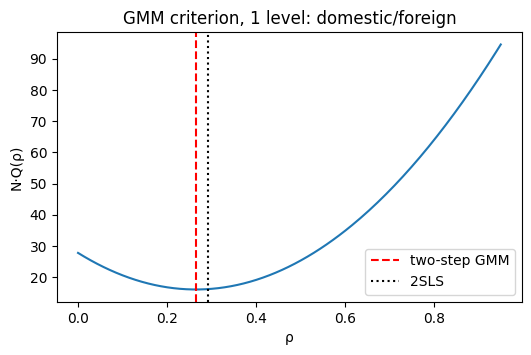

In [8]:
# The GMM criterion: a line over rho for one level, a contour for two levels (section 7.3 of the note)
try:
    import matplotlib.pyplot as plt
    k = len(terms)
    if k == 1:
        grid = np.linspace(0, 0.95, 200)
        fig, ax = plt.subplots(figsize=(6, 3.5))
        ax.plot(grid, [gmm_obj.N * gmm_obj.Q([r], gmm2["W"]) for r in grid])
        ax.axvline(gmm2["rho"][0], color="r", ls="--", label="two-step GMM")
        if 0 <= b_iv[list(terms)[0]] <= 0.95:
            ax.axvline(b_iv[list(terms)[0]], color="k", ls=":", label="2SLS")
        ax.set_xlabel("ρ"); ax.set_ylabel("N·Q(ρ)"); ax.set_title(f"GMM criterion, {NEST_LABELS[NEST]}")
        ax.legend(); plt.show()
    elif k == 2:
        grid = np.linspace(0, 0.95, 60)
        Qg = np.array([[gmm_obj.N * gmm_obj.Q((r1, r2), gmm2["W"]) for r1 in grid] for r2 in grid])
        fig, ax = plt.subplots(figsize=(6, 5))
        cs = ax.contourf(grid, grid, np.log(Qg), levels=30, cmap="viridis"); fig.colorbar(cs, label="log N·Q")
        ax.plot(grid, grid, "w--", lw=1, label="ρ2 = ρ1"); ax.plot(*gmm2["rho"], "r*", ms=14, label="two-step GMM")
        ax.set_xlabel("ρ1 (subnest)"); ax.set_ylabel("ρ2 (nest)"); ax.legend(loc="upper left"); plt.show()
except ImportError:
    print("matplotlib not installed: skipping the plot.")

In [9]:
if ESTIMATOR == "gmm":
    alpha, theta2, delta_hat = gmm2["alpha"], gmm2["theta2"], gmm2["delta"]
else:
    alpha = -b_iv[PRICE_COL]
    theta2 = theta2_from([b_iv[k] for k in terms])
    delta_hat = y - sum(b_iv[k] * terms[k] for k in terms)      # D^{-1}(S; theta2)
df["delta"] = delta_hat
rho1, rho2 = theta2
print(f"Estimator: {ESTIMATOR}. alpha = {alpha:.3f}, rho1 = {rho1:.3f}, rho2 = {rho2:.3f}")
if alpha > 0 and 0 <= rho2 <= rho1 < 1:
    print("Consistent with random utility maximisation: alpha > 0 and 0 <= rho2 <= rho1 < 1")
else:
    print("WARNING: restrictions violated. The nesting structure is fighting the data (note, §5.4).")

Estimator: 2sls. alpha = 2.669, rho1 = 0.292, rho2 = 0.292
Consistent with random utility maximisation: alpha > 0 and 0 <= rho2 <= rho1 < 1


## 6. The market model: shares, $\nabla s$, elasticities and diversion
Within one market, the class computes the shares from the inclusive values, using the two-level formulas, which also cover one level and the simple logit:

$$I_{hg} = (1-\rho_1)\log\!\sum_{k\in B_{hg}} e^{\delta_k/(1-\rho_1)}, \qquad I_g = (1-\rho_2)\log\!\sum_{h\in g} e^{I_{hg}/(1-\rho_2)}, \qquad \delta_j(p) = \hat\delta_j - \alpha\big(f(p_j)-f(p_j^0)\big)$$

The Jacobian is

$$\frac{\partial s_k}{\partial p_j} = -\alpha f'(p_j)\, s_k\Big[\frac{\mathbb 1\{j=k\}}{1-\rho_1} - \Big(\frac{1}{1-\rho_1}-\frac{1}{1-\rho_2}\Big)\mathbb 1\{h_j=h_k\}s_{j|hg} - \Big(\frac{1}{1-\rho_2}-1\Big)\mathbb 1\{g_j=g_k\}s_{j|g} - s_j\Big]$$

Firms set producer prices $r = p/(1+\tau)$, where $\tau$ is VAT.

In [10]:
class NestedLogitMarket:
    """(Nested) logit for one market. p in princ units (consumer price incl. VAT)."""

    def __init__(self, m, alpha, theta2):
        self.m = m.reset_index(drop=True)
        self.alpha = float(alpha)
        self.rho1, self.rho2 = float(theta2[0]), float(theta2[1])
        self.hg, self.g = self.m["hg"].values, self.m["g"].values
        self.same_hg = (self.hg[:, None] == self.hg[None, :]).astype(float)
        self.same_g = (self.g[:, None] == self.g[None, :]).astype(float)
        self.hg_codes, self.g_codes = np.unique(self.hg), np.unique(self.g)
        self.g_of_hg = np.array([self.g[self.hg == h][0] for h in self.hg_codes])
        self.p0 = self.m["princ"].to_numpy(dtype=float)
        self.delta0 = self.m["delta"].to_numpy(dtype=float)
        self.tau = self.m["tax"].to_numpy(dtype=float)
        self.M = float(self.m["M"].iloc[0])

    def shares(self, p):
        r1, r2 = self.rho1, self.rho2
        v = (self.delta0 - self.alpha * (price_term(p) - price_term(self.p0))) / (1 - r1)
        I_hg = np.array([(1 - r1) * logsumexp(v[self.hg == h]) for h in self.hg_codes])
        I_g = np.array([(1 - r2) * logsumexp(I_hg[self.g_of_hg == g] / (1 - r2)) for g in self.g_codes])
        logsum = np.logaddexp(0.0, logsumexp(I_g))
        I_hg_j = I_hg[np.searchsorted(self.hg_codes, self.hg)]
        I_g_j = I_g[np.searchsorted(self.g_codes, self.g)]
        s_j_hg = np.exp(v - I_hg_j / (1 - r1))
        s_h_g = np.exp((I_hg_j - I_g_j) / (1 - r2))
        s = s_j_hg * s_h_g * np.exp(I_g_j - logsum)
        return {"s": s, "s_j_hg": s_j_hg, "s_j_g": s_j_hg * s_h_g, "s0": np.exp(-logsum), "logsum": logsum}

    def grad_s(self, p):
        """nabla s = [d s_k / d p_j], rows j, columns k."""
        sh = self.shares(p)
        s = sh["s"]
        a = 1 / (1 - self.rho1) - 1 / (1 - self.rho2)
        b = 1 / (1 - self.rho2) - 1
        bracket = (np.eye(len(s)) / (1 - self.rho1) - a * self.same_hg * sh["s_j_hg"][:, None]
                   - b * self.same_g * sh["s_j_g"][:, None] - s[:, None])
        return -self.alpha * price_term_deriv(p)[:, None] * s[None, :] * bracket

    def ownership(self, merger=None):
        f = self.m["frm"].values.copy()
        if merger is not None:
            f[f == merger[1]] = merger[0]
        return (f[:, None] == f[None, :]).astype(float)

    def grad_s_r(self, p):
        return self.grad_s(p) * (1 + self.tau)[:, None]

    def foc(self, r, c, H):
        p = r * (1 + self.tau)
        return self.shares(p)["s"] + (H * self.grad_s_r(p)) @ (r - c)

    def recover_costs(self):
        r0 = self.p0 / (1 + self.tau)
        return r0 + np.linalg.solve(self.ownership() * self.grad_s_r(self.p0), self.shares(self.p0)["s"])

    def solve(self, c, H, r_start):
        sol = root(self.foc, r_start, args=(c, H), method="hybr", tol=1e-12)
        if np.max(np.abs(sol.fun)) > 1e-10:
            raise RuntimeError(f"Equilibrium solver did not converge: {sol.message}")
        return sol.x

    def elasticities(self):
        G = self.grad_s(self.p0)
        s = self.shares(self.p0)["s"]
        return G.T * self.p0[None, :] / s[:, None]            # E[j,k] = (ds_j/dp_k)(p_k/s_j)

    def diversion(self):
        G = self.grad_s(self.p0)
        return -G / np.diag(G)[:, None]                        # D[j,k]: share of j's lost sales going to k

In [11]:
m = df[(df["ma"] == MARKET) & (df["ye"] == YEAR)].copy()
for f in (BUYER, SELLER):
    assert f in set(m["frm"]), f"{firm_name(f)} has no products in this market-year"
mk = NestedLogitMarket(m, alpha, theta2)

# Checks: shares reproduce the data; analytical Jacobian = numerical (central differences)
s_pre = mk.shares(mk.p0)["s"]
assert np.allclose(s_pre, m["S"].values, rtol=1e-6)
h, I_ = 1e-6, np.eye(len(m))
num = np.array([(mk.shares(mk.p0 + h * I_[j])["s"] - mk.shares(mk.p0 - h * I_[j])["s"]) / (2 * h)
                for j in range(len(m))])
G0 = mk.grad_s(mk.p0)
assert np.abs(num - G0).max() / np.abs(G0).max() < 1e-6, "Jacobian check failed"

m["E_own"] = np.diag(mk.elasticities())
print(f"{market_name(MARKET)} 19{YEAR}: {len(m)} cars. Checks passed.")
m["E_own"].describe().to_frame("own-price elasticity").T

Germany 1998: 40 cars. Checks passed.


,count,mean,std,min,25%,50%,75%,max
own-price elasticity,40.0000,-3.7044,0.0341,-3.7425,-3.7235,-3.7147,-3.6963,-3.5519


**Diversion between VW and Fiat.** $D_{jk}$ is the share of $j$'s lost sales that go to $k$ when $j$ raises its price. The table shows, for each car of each merging firm, the total diversion to the other firm's cars and to the outside good.

In [13]:
D = mk.diversion()
fb, fs = (m["frm"] == BUYER).values, (m["frm"] == SELLER).values
div_rows = []
for i in np.where(fb | fs)[0]:
    other = fs if fb[i] else fb
    div_rows.append({"car": m["type"].iloc[i], "firm": firm_name(m["frm"].iloc[i]),
                     "share %": 100 * s_pre[i],
                     "to other merging firm %": 100 * D[i, other].sum(),
                     "to own firm's other cars %": 100 * (D[i, (fb if fb[i] else fs)].sum() - D[i, i]),
                     "to outside good %": 100 * (1 - (D[i].sum() - D[i, i]))})
div_tab = pd.DataFrame(div_rows).sort_values(["firm", "share %"], ascending=[True, False]).set_index("car")
agg = {f"{firm_name(SELLER)} → {firm_name(BUYER)}": 100 * np.average(D[np.ix_(fs, fb)].sum(1), weights=s_pre[fs]),
       f"{firm_name(BUYER)} → {firm_name(SELLER)}": 100 * np.average(D[np.ix_(fb, fs)].sum(1), weights=s_pre[fb])}
print("Share-weighted diversion between the merging firms: " + ", ".join(f"{k}: {v:.1f}%" for k, v in agg.items()))
div_tab.style.format({c: "{:.2f}" for c in div_tab.columns if c != "firm"})

Share-weighted diversion between the merging firms: Fiat → VW: 6.1%, VW → Fiat: 0.5%


,firm,share %,to other merging firm %,to own firm's other cars %,to outside good %
car,,,,,
fiat punto,Fiat,0.27,6.15,1.16,62.90
fiat bravo/brava,Fiat,0.11,6.05,2.77,61.87
volkswagen golf,VW,1.65,0.29,9.18,64.90
volkswagen passat,VW,0.78,0.28,12.01,62.88
volkswagen polo,VW,0.53,0.28,12.79,62.33
audi a4,VW,0.48,0.28,12.96,62.21
audi a6,VW,0.34,0.27,13.37,61.91
audi a3,VW,0.29,0.27,13.52,61.80
skoda octavia,VW,0.12,3.92,4.81,61.93


## 7. Marginal costs from the pre-merger FOCs
$$\hat c = r + \big(H\odot\nabla_r s\big)^{-1}s, \qquad r = p/(1+\tau),\quad \nabla_r s = (1+\tau)\nabla s$$
The markup is $\eta = r-\hat c$ and the Lerner index is $\eta/r$. A negative $\hat c$ is the note's diagnostic that something in the chain is wrong.

In [14]:
c_hat = mk.recover_costs()
r0 = mk.p0 / (1 + mk.tau)
m["c"], m["eta"] = c_hat, r0 - c_hat
m["lerner"] = m["eta"] / r0
assert np.allclose(mk.solve(c_hat, mk.ownership(), r0), r0, rtol=1e-6), "pre-merger equilibrium not reproduced"
if (c_hat <= 0).any():
    print(f"WARNING: {np.sum(c_hat <= 0)} cars have non-positive marginal cost")
m["lerner"].describe().to_frame("Lerner index").T

,count,mean,std,min,25%,50%,75%,max
Lerner index,40.0000,0.2847,0.0142,0.2681,0.2746,0.2797,0.2910,0.3344


## 8. Merger simulation
The merger replaces $H$ with $H'$ and solves (3.3) for the new prices, holding $\hat\delta$ and $\hat\theta$ fixed. The merging firms' costs are $c' = \hat c(1-\kappa)$.

With log price, the log-sum is not in money units (§3.5 of the note). The change in consumer surplus is therefore the area under demand (trapezoid rule):
$$\Delta CS_t \approx -\sum_j \tfrac12\big(q_j^{old}+q_j^{new}\big)\big(p_j^{new}-p_j^{old}\big)$$
With price in levels, the exact log-sum formula is used.

In [15]:
def consumer_surplus_change(mk, pre, post, out):
    if PRICE_SPEC == "levels":
        return mk.M / mk.alpha * (post["logsum"] - pre["logsum"])
    return -np.sum(0.5 * (out["q_pre"] + out["q_post"]) * (out["p_post"] - out["p_pre"]))


def simulate_merger(mk, c, buyer=BUYER, seller=SELLER, kappa=KAPPA):
    r0 = mk.p0 / (1 + mk.tau)
    merging = mk.m["frm"].isin([buyer, seller]).values
    c_new = np.where(merging, c * (1 - kappa), c)
    r1 = mk.solve(c_new, mk.ownership((buyer, seller)), c_new + (r0 - c))   # start: old markups on new costs
    p1 = r1 * (1 + mk.tau)
    pre, post = mk.shares(mk.p0), mk.shares(p1)
    out = mk.m.copy()
    out["merging"] = merging
    out["p_pre"], out["p_post"] = mk.p0, p1
    out["dp_pct"] = 100 * (p1 / mk.p0 - 1)
    out["q_pre"], out["q_post"] = pre["s"] * mk.M, post["s"] * mk.M
    out["profit_pre"], out["profit_post"] = (r0 - c) * out["q_pre"], (r1 - c_new) * out["q_post"]
    return out, consumer_surplus_change(mk, pre, post, out)


def eur_factor(mm):
    """princ units -> EUR: x (ngdp/pop) gives local currency, / avdexr gives SDR, x 1.2956 gives EUR."""
    return (mm["ngdp"] / mm["pop"]).iloc[0] * 1.2956 / mm["avdexr"].iloc[0]


res, dCS = simulate_merger(mk, c_hat)
res["firm"] = res["frm"].map(firm_name)
for col in ["c", "eta", "lerner", "E_own"]:
    res[col] = m[col].values
print(f"{firm_name(BUYER)} acquires {firm_name(SELLER)} in {market_name(MARKET)} 19{YEAR}, kappa = {KAPPA:.0%}")

VW acquires Fiat in Germany 1998, kappa = 0%


## 9. Results and welfare

In [16]:
firm_tab = (res.groupby("firm")
            .apply(lambda d: pd.Series({
                "share_pre_%": 100 * d["q_pre"].sum() / res["q_pre"].sum(),
                "share_post_%": 100 * d["q_post"].sum() / res["q_post"].sum(),
                "avg_dp_%": np.average(d["dp_pct"], weights=d["q_pre"]),
                "merging": d["merging"].iloc[0]}), include_groups=False)
            .sort_values("share_pre_%", ascending=False))
firm_tab.head(12)

,share_pre_%,share_post_%,avg_dp_%,merging
firm,,,,
VW,32.1693,32.1178,0.1684,True
GeneralMotors,18.3782,18.4538,0.0038,False
Mercedes,10.9524,10.9981,0.0022,False
Ford,10.6886,10.7332,0.0022,False
BMW,7.3438,7.3746,0.0014,False
Renault,5.6607,5.7036,0.0643,False
Fiat,2.8021,2.5036,3.3102,True
Nissan,2.6968,2.7208,0.0295,False
Mazda,2.5709,2.5940,0.0273,False


In [17]:
def summarise(res, dCS, mm, buyer=BUYER):
    mg = res["merging"]
    hhi = lambda q: 10000 * ((q / q.sum()) ** 2).sum()
    eur = eur_factor(mm)
    return pd.Series({
        "Price change, all cars (%)": np.average(res["dp_pct"], weights=res["q_pre"]),
        "Price change, merging firms (%)": np.average(res.loc[mg, "dp_pct"], weights=res.loc[mg, "q_pre"]),
        "HHI pre": hhi(res.groupby("frm")["q_pre"].sum()),
        "ΔHHI (at pre-merger shares)": hhi(res.assign(f=np.where(mg, buyer, res["frm"])).groupby("f")["q_pre"].sum())
                                        - hhi(res.groupby("frm")["q_pre"].sum()),
        "ΔCS (EUR m)": dCS * eur / 1e6,
        "ΔPS (EUR m)": (res["profit_post"].sum() - res["profit_pre"].sum()) * eur / 1e6,
        "  of which merging firms (EUR m)": (res.loc[mg, "profit_post"].sum() - res.loc[mg, "profit_pre"].sum()) * eur / 1e6,
    })

summarise(res, dCS, m).to_frame(f"{firm_name(BUYER)}–{firm_name(SELLER)}, {market_name(MARKET)} 19{YEAR}").style.format("{:,.2f}")

,"VW–Fiat, Germany 1998"
"Price change, all cars (%)",0.15
"Price change, merging firms (%)",0.42
HHI pre,"1,725.34"
ΔHHI (at pre-merger shares),180.28
ΔCS (EUR m),-47.83
ΔPS (EUR m),17.20
of which merging firms (EUR m),1.49


In [18]:
cols = ["co", "type", "firm", "cla", "home", "merging", "p_pre", "p_post", "dp_pct",
        "q_pre", "q_post", "E_own", "c", "eta", "lerner"]
product_tab = res[cols].sort_values("dp_pct", ascending=False)
product_tab.to_csv(f"merger_results_v2_{market_name(MARKET)}_{YEAR}.csv", index=False)
product_tab.head(10)

,co,type,firm,cla,home,merging,p_pre,p_post,dp_pct,q_pre,q_post,E_own,c,eta,lerner
2,69,fiat punto,Fiat,1,0,True,0.3955,0.4095,3.5342,"55,503.0000","49,015.7173",-3.6651,0.2466,0.0944,0.2769
30,850,fiat bravo/brava,Fiat,2,0,True,0.5055,0.5195,2.7655,"22,831.0000","20,736.7581",-3.7259,0.3162,0.1196,0.2744
31,852,skoda felicia,VW,1,0,True,0.3711,0.3775,1.7150,"18,393.0000","17,365.3569",-3.7342,0.2263,0.0937,0.2927
21,243,seat ibiza,VW,1,0,True,0.4148,0.4212,1.5344,"19,350.0000","18,391.6619",-3.7324,0.2540,0.1037,0.2899
38,921,skoda octavia,VW,3,0,True,0.5167,0.5231,1.2319,"24,872.0000","23,907.5294",-3.7221,0.3185,0.1270,0.2850
23,284,volkswagen polo,VW,1,1,True,0.4456,0.4461,0.1036,"109,047.0000","108,715.2803",-3.6988,0.2557,0.1285,0.3344
24,285,volkswagen golf,VW,2,1,True,0.5767,0.5772,0.0800,"338,932.0000","338,200.6242",-3.5519,0.3387,0.1585,0.3187
20,216,renault twingo,Renault,1,0,False,0.3703,0.3706,0.0796,"58,514.0000","58,724.5047",-3.6595,0.2251,0.0941,0.2949
19,203,renault clio,Renault,1,0,False,0.4349,0.4352,0.0678,"30,551.0000","30,674.5713",-3.7115,0.2660,0.1089,0.2905
34,880,audi a3,VW,2,1,True,0.7194,0.7198,0.0642,"60,003.0000","59,909.3207",-3.7301,0.4290,0.1911,0.3081


## 10. The same merger in all five markets
The same $\hat\theta$ is used in every country in `YEAR`.

In [19]:
def merger_in_market(ma, ye, d, alpha_, theta2_, kappa=KAPPA):
    mm = d[(d["ma"] == ma) & (d["ye"] == ye)]
    if not {BUYER, SELLER} <= set(mm["frm"]):
        return None
    mk_t = NestedLogitMarket(mm, alpha_, theta2_)
    c_t = mk_t.recover_costs()
    r_t, dcs_t = simulate_merger(mk_t, c_t, kappa=kappa)
    s_t = mk_t.shares(mk_t.p0)["s"]
    D_t = mk_t.diversion()
    fb_t, fs_t = (mm["frm"] == BUYER).values, (mm["frm"] == SELLER).values
    out = summarise(r_t, dcs_t, mm)
    out[f"{firm_name(BUYER)} share %"] = 100 * s_t[fb_t].sum() / s_t.sum()
    out[f"{firm_name(SELLER)} share %"] = 100 * s_t[fs_t].sum() / s_t.sum()
    out[f"diversion {firm_name(SELLER)}→{firm_name(BUYER)} %"] = 100 * np.average(D_t[np.ix_(fs_t, fb_t)].sum(1), weights=s_t[fs_t])
    out["cars with c ≤ 0"] = int((c_t <= 0).sum())
    return out

all_mkts = {market_name(ma): merger_in_market(ma, YEAR, df, alpha, theta2) for ma in sorted(df["ma"].unique())}
all_tab = pd.DataFrame({k: v for k, v in all_mkts.items() if v is not None}).T
all_tab.style.format("{:,.2f}")

,"Price change, all cars (%)","Price change, merging firms (%)",HHI pre,ΔHHI (at pre-merger shares),ΔCS (EUR m),ΔPS (EUR m),of which merging firms (EUR m),VW share %,Fiat share %,diversion Fiat→VW %,cars with c ≤ 0
Belgium,0.22,0.86,"1,242.41",120.43,-7.79,2.70,0.30,21.47,2.80,8.31,0.00
France,0.54,3.03,"2,183.63",130.79,-86.19,26.43,4.10,11.50,5.69,9.85,0.00
Germany,0.15,0.42,"1,725.34",180.28,-47.83,17.20,1.49,32.17,2.80,6.12,0.00
Italy,0.73,1.33,"2,220.60","1,076.94",-148.24,19.18,2.04,12.95,41.59,1.28,0.00
UK,0.21,1.49,"1,235.28",78.75,-54.27,19.71,1.46,9.31,4.23,5.73,0.00


## 11. Model comparison across nest structures
The model is re-estimated for every structure in `NEST_OPTIONS`, with the same fixed effects, characteristics, type of instruments and estimator. The instruments are rebuilt at each structure's own nest levels. Structures that violate $0 \le \rho_2 \le \rho_1 < 1$ are flagged, and their merger results are not shown.

In [21]:
def estimate_structure(nest, kind=INSTRUMENTS, fe=FIXED_EFFECTS, chars=CHARACTERISTICS, estimator=ESTIMATOR):
    d, tm = nest_setup(base, nest)
    Zx = build_instruments(d, kind, nest)
    ex = d[chars].astype(float).join(fixed_effects(d, fe))
    en = pd.DataFrame({PRICE_COL: price_term(d["princ"]), **tm})
    F = first_stage_F(en, ex, Zx)
    gm = NestedLogitGMM(d["y"], price_term(d["princ"]), tm, Zx, ex, d[CLUSTER]).fit(two_step=True)
    if estimator == "gmm":
        a, rho, dlt = gm["alpha"], list(gm["rho"]), gm["delta"]
    else:
        b, se = iv2sls(d["y"], en.join(ex), Zx.join(ex), d[CLUSTER])
        a, rho = -b[PRICE_COL], [b[k] for k in tm]
        dlt = d["y"] - sum(b[k] * tm[k] for k in tm)
    th = theta2_from(rho)
    valid = bool(a > 0 and 0 <= th[1] <= th[0] < 1)
    info = {"alpha": a, "rho1": th[0] if rho else np.nan, "rho2": th[1] if len(rho) == 2 else np.nan,
            "#IV": Zx.shape[1], "min first-stage F": F.min(), "J p-value": gm["J_p"], "valid": valid}
    return d.assign(delta=dlt), a, th, valid, info


comp_est, comp_res = {}, {}
for nest in NEST_OPTIONS:
    d_n, a_n, th_n, ok, info = estimate_structure(nest)
    comp_est[NEST_LABELS[nest]] = info
    if ok:
        comp_res[NEST_LABELS[nest]] = merger_in_market(MARKET, YEAR, d_n, a_n, th_n)
display(pd.DataFrame(comp_est).T.style.format({c: "{:,.3f}" for c in ["alpha", "rho1", "rho2", "min first-stage F", "J p-value"]}))
pd.DataFrame(comp_res).style.format("{:,.2f}")

,alpha,rho1,rho2,#IV,min first-stage F,J p-value,valid
Simple logit,3.305,nan,nan,6,68.730,0.111,True
1 level: domestic/foreign,2.669,0.292,nan,12,27.795,0.099,True
1 level: segment,3.723,0.026,nan,12,41.281,0.094,True
1 level: segment × dom/for,3.565,0.091,nan,12,41.573,0.158,True
2 levels: segment → dom/for,3.309,0.042,-0.178,18,29.305,0.002,False
2 levels: dom/for → segment,1.979,0.360,0.403,18,28.749,0.066,False


,Simple logit,1 level: domestic/foreign,1 level: segment,1 level: segment × dom/for
"Price change, all cars (%)",0.13,0.15,0.12,0.12
"Price change, merging firms (%)",0.36,0.42,0.33,0.33
HHI pre,"1,725.34","1,725.34","1,725.34","1,725.34"
ΔHHI (at pre-merger shares),180.28,180.28,180.28,180.28
ΔCS (EUR m),-41.05,-47.83,-38.04,-37.40
ΔPS (EUR m),5.32,17.20,5.49,6.74
of which merging firms (EUR m),0.82,1.49,0.83,0.90
VW share %,32.17,32.17,32.17,32.17
Fiat share %,2.80,2.80,2.80,2.80
diversion Fiat→VW %,4.40,6.12,5.03,5.14


## 12. Own- and cross-price elasticity matrices
$E_{jk} = \partial\log s_j/\partial\log p_k$: row $j$ is the car whose sales respond and column $k$ is the car whose price changes. Under the simple logit every column is constant off the diagonal (IIA). Under the nested logit a column takes one value for cars in the same nest and another for cars in other nests.

In [22]:
ELAST_CARS = ["volkswagen polo", "fiat punto", "opel corsa", "renault clio",
              "volkswagen golf", "opel astra", "fiat bravo/brava", "toyota corolla",
              "volkswagen passat", "BMW 3"]
ELAST_MARKETS = [3, 4, 2]
SEGMENT = {1: "subcompact", 2: "compact", 3: "intermediate", 4: "standard", 5: "luxury"}


def elasticity_matrix(mm, alpha_, theta2_, cars=ELAST_CARS):
    mk_e = NestedLogitMarket(mm, alpha_, theta2_)
    E_full = mk_e.elasticities()
    types = mk_e.m["type"].values
    idx = [int(np.where(types == c)[0][0]) for c in cars if c in types]
    missing = [c for c in cars if c not in types]
    if missing:
        print(f"Not among the 40 best-sellers here: {missing}")
    lab = [f"{types[i]} ({SEGMENT[int(mk_e.m['cla'].iloc[i])]}, {'dom' if mk_e.m['home'].iloc[i] == 1 else 'for'})" for i in idx]
    return pd.DataFrame(E_full[np.ix_(idx, idx)], index=lab, columns=[l.split(" (")[0] for l in lab])


def style_elasticities(E):
    off = E.values[~np.eye(len(E), dtype=bool)]
    top = off.max() if off.size and off.max() > 0 else 1.0
    def css(df_):
        out = pd.DataFrame("", index=df_.index, columns=df_.columns)
        for i in range(len(df_)):
            for j in range(len(df_.columns)):
                if i == j:
                    out.iat[i, j] = "background-color: #d9d9d9; font-weight: bold; color: #000"
                else:
                    a_ = min(max(df_.iat[i, j] / top, 0), 1)
                    out.iat[i, j] = f"background-color: rgba(31, 119, 180, {0.08 + 0.72 * a_:.2f}); color: #000"
        return out
    return E.style.apply(css, axis=None).format("{:.3f}")


for ma in ELAST_MARKETS:
    mm = df[(df["ma"] == ma) & (df["ye"] == YEAR)]
    display(Markdown(f"**{market_name(ma)} 19{YEAR}: {NEST_LABELS[NEST]}**"))
    display(style_elasticities(elasticity_matrix(mm, alpha, theta2)))

d_l, a_l, th_l, _, _ = estimate_structure("logit")
mm = d_l[(d_l["ma"] == ELAST_MARKETS[0]) & (d_l["ye"] == YEAR)]
display(Markdown(f"**{market_name(ELAST_MARKETS[0])} 19{YEAR}: simple logit (IIA: constant columns)**"))
display(style_elasticities(elasticity_matrix(mm, a_l, th_l)))

**Germany 1998: 1 level: domestic/foreign**

,volkswagen polo,fiat punto,opel corsa,renault clio,volkswagen golf,opel astra,fiat bravo/brava,toyota corolla,volkswagen passat,BMW 3
"volkswagen polo (subcompact, dom)",-3.699,0.007,0.082,0.004,0.217,0.141,0.003,0.005,0.102,0.079
"fiat punto (subcompact, for)",0.014,-3.665,0.017,0.057,0.044,0.029,0.043,0.071,0.021,0.016
"opel corsa (subcompact, dom)",0.070,0.007,-3.686,0.004,0.217,0.141,0.003,0.005,0.102,0.079
"renault clio (subcompact, for)",0.014,0.103,0.017,-3.712,0.044,0.029,0.043,0.071,0.021,0.016
"volkswagen golf (compact, dom)",0.070,0.007,0.082,0.004,-3.552,0.141,0.003,0.005,0.102,0.079
"opel astra (compact, dom)",0.070,0.007,0.082,0.004,0.217,-3.628,0.003,0.005,0.102,0.079
"fiat bravo/brava (compact, for)",0.014,0.103,0.017,0.057,0.044,0.029,-3.726,0.071,0.021,0.016
"toyota corolla (compact, for)",0.014,0.103,0.017,0.057,0.044,0.029,0.043,-3.697,0.021,0.016
"volkswagen passat (intermediate, dom)",0.070,0.007,0.082,0.004,0.217,0.141,0.003,0.005,-3.666,0.079
"BMW 3 (standard, dom)",0.070,0.007,0.082,0.004,0.217,0.141,0.003,0.005,0.102,-3.690


**Italy 1998: 1 level: domestic/foreign**

,volkswagen polo,fiat punto,opel corsa,renault clio,volkswagen golf,opel astra,fiat bravo/brava,toyota corolla,volkswagen passat,BMW 3
"volkswagen polo (subcompact, for)",-3.677,0.054,0.128,0.081,0.072,0.076,0.015,0.018,0.040,0.023
"fiat punto (subcompact, dom)",0.014,-3.306,0.020,0.013,0.011,0.012,0.132,0.003,0.006,0.004
"opel corsa (subcompact, for)",0.092,0.054,-3.640,0.081,0.072,0.076,0.015,0.018,0.040,0.023
"renault clio (subcompact, for)",0.092,0.054,0.128,-3.687,0.072,0.076,0.015,0.018,0.040,0.023
"volkswagen golf (compact, for)",0.092,0.054,0.128,0.081,-3.696,0.076,0.015,0.018,0.040,0.023
"opel astra (compact, for)",0.092,0.054,0.128,0.081,0.072,-3.693,0.015,0.018,0.040,0.023
"fiat bravo/brava (compact, dom)",0.014,0.462,0.020,0.013,0.011,0.012,-3.636,0.003,0.006,0.004
"toyota corolla (compact, for)",0.092,0.054,0.128,0.081,0.072,0.076,0.015,-3.750,0.040,0.023
"volkswagen passat (intermediate, for)",0.092,0.054,0.128,0.081,0.072,0.076,0.015,0.018,-3.728,0.023
"BMW 3 (standard, for)",0.092,0.054,0.128,0.081,0.072,0.076,0.015,0.018,0.040,-3.746


**France 1998: 1 level: domestic/foreign**

,volkswagen polo,fiat punto,opel corsa,renault clio,volkswagen golf,opel astra,fiat bravo/brava,toyota corolla,volkswagen passat,BMW 3
"volkswagen polo (subcompact, for)",-3.662,0.118,0.106,0.030,0.113,0.063,0.044,0.013,0.041,0.036
"fiat punto (subcompact, for)",0.107,-3.650,0.106,0.030,0.113,0.063,0.044,0.013,0.041,0.036
"opel corsa (subcompact, for)",0.107,0.118,-3.663,0.030,0.113,0.063,0.044,0.013,0.041,0.036
"renault clio (subcompact, dom)",0.010,0.011,0.010,-3.550,0.010,0.006,0.004,0.001,0.004,0.003
"volkswagen golf (compact, for)",0.107,0.118,0.106,0.030,-3.655,0.063,0.044,0.013,0.041,0.036
"opel astra (compact, for)",0.107,0.118,0.106,0.030,0.113,-3.705,0.044,0.013,0.041,0.036
"fiat bravo/brava (compact, for)",0.107,0.118,0.106,0.030,0.113,0.063,-3.725,0.013,0.041,0.036
"toyota corolla (compact, for)",0.107,0.118,0.106,0.030,0.113,0.063,0.044,-3.755,0.041,0.036
"volkswagen passat (intermediate, for)",0.107,0.118,0.106,0.030,0.113,0.063,0.044,0.013,-3.727,0.036
"BMW 3 (standard, for)",0.107,0.118,0.106,0.030,0.113,0.063,0.044,0.013,0.041,-3.732


**Germany 1998: simple logit (IIA: constant columns)**

,volkswagen polo,fiat punto,opel corsa,renault clio,volkswagen golf,opel astra,fiat bravo/brava,toyota corolla,volkswagen passat,BMW 3
"volkswagen polo (subcompact, dom)",-3.287,0.009,0.021,0.005,0.055,0.035,0.004,0.006,0.026,0.020
"fiat punto (subcompact, for)",0.018,-3.296,0.021,0.005,0.055,0.035,0.004,0.006,0.026,0.020
"opel corsa (subcompact, dom)",0.018,0.009,-3.284,0.005,0.055,0.035,0.004,0.006,0.026,0.020
"renault clio (subcompact, for)",0.018,0.009,0.021,-3.300,0.055,0.035,0.004,0.006,0.026,0.020
"volkswagen golf (compact, dom)",0.018,0.009,0.021,0.005,-3.250,0.035,0.004,0.006,0.026,0.020
"opel astra (compact, dom)",0.018,0.009,0.021,0.005,0.055,-3.269,0.004,0.006,0.026,0.020
"fiat bravo/brava (compact, for)",0.018,0.009,0.021,0.005,0.055,0.035,-3.301,0.006,0.026,0.020
"toyota corolla (compact, for)",0.018,0.009,0.021,0.005,0.055,0.035,0.004,-3.299,0.026,0.020
"volkswagen passat (intermediate, dom)",0.018,0.009,0.021,0.005,0.055,0.035,0.004,0.006,-3.279,0.020
"BMW 3 (standard, dom)",0.018,0.009,0.021,0.005,0.055,0.035,0.004,0.006,0.026,-3.285


## 13. Break-even cost savings
The assignment asks how large the cost savings would have to be for the merger to be net positive for consumers. For each market, $\kappa^*$ solves $\Delta CS(\kappa) = 0$, where the merging firms' marginal costs are cut by $\kappa$. The cell also reports the smaller $\kappa$ at which the merging firms' average price is unchanged.

In [23]:
def break_even(ma, ye, d=df, alpha_=alpha, theta2_=theta2):
    mm = d[(d["ma"] == ma) & (d["ye"] == ye)]
    if not {BUYER, SELLER} <= set(mm["frm"]):
        return None
    mk_b = NestedLogitMarket(mm, alpha_, theta2_)
    c_b = mk_b.recover_costs()
    cs = lambda k: simulate_merger(mk_b, c_b, kappa=k)[1]
    def dp(k):
        r_, _ = simulate_merger(mk_b, c_b, kappa=k)
        return np.average(r_.loc[r_.merging, "dp_pct"], weights=r_.loc[r_.merging, "q_pre"])
    def root_in(f):
        """Find the kappa where f changes sign, widening the bracket step by step."""
        for hi in [0.01, 0.02, 0.05, 0.1, 0.2]:
            if f(hi) > 0 if f is cs else f(hi) < 0:
                return 100 * brentq(f, 0.0, hi, xtol=1e-9)
        return np.nan
    return pd.Series({"κ* for ΔCS = 0 (%)": root_in(cs),
                      "κ for no price change, merging firms (%)": root_in(dp),
                      "ΔCS at κ = 0 (EUR m)": cs(0.0) * eur_factor(mm) / 1e6})

be = pd.DataFrame({market_name(ma): break_even(ma, YEAR) for ma in sorted(df["ma"].unique())}).T
be.style.format("{:,.2f}")

,κ* for ΔCS = 0 (%),"κ for no price change, merging firms (%)",ΔCS at κ = 0 (EUR m)
Belgium,0.69,0.97,-7.79
France,2.83,3.45,-86.19
Germany,0.34,0.50,-47.83
Italy,1.41,1.52,-148.24
UK,1.40,1.64,-54.27


## 14. Scenario grid: fixed effects × characteristics × instruments × nests
This is the specification search behind the baseline. Every combination is estimated by 2SLS and checked against the following criteria:

- **Valid:** $\alpha > 0$ and $0 \le \rho_2 \le \rho_1 < 1$.
- **Credible:** valid, plus minimum first-stage $F \ge 10$, no negative marginal costs, and mean own elasticity between −2 and −12 in the main market.
- **Best:** credible, plus the J test does not reject ($p \ge 0.05$, two-step GMM) and ρ is significant ($t > 1.96$).

Report this table rather than hiding it: the baseline was chosen with it, and it doubles as the robustness check.

The grid takes about 8 minutes, so by default (`RUN_GRID = False`) the notebook loads the saved results from `scenario_grid_v2.csv`. Set `RUN_GRID = True` to recompute them, for example after changing `DIVISOR` or `PRICE_SPEC`.

In [21]:
GRID_FE = {"mkt + brand": ["mkt", "brd"], "mkt + brand + segment": ["mkt", "brd", "cla"],
           "mkt + firm": ["mkt", "frm"], "mkt + model": ["mkt", "zcode"]}
GRID_CHARS = {"we, li, home": ["log_we", "log_li", "home"], "all": CHARACTERISTICS}
GRID_IV = ["gh", "gh_counts_xexr", "nest_sums", "counts"]


def grid_row(nest, fe_name, ch_name, kind):
    d, tm = nest_setup(base, nest)
    if nest == "logit" and kind in ("nest_sums", "counts"):
        return None
    Zx = build_instruments(d, kind, nest)
    ex = d[GRID_CHARS[ch_name]].astype(float).join(fixed_effects(d, GRID_FE[fe_name]))
    en = pd.DataFrame({PRICE_COL: price_term(d["princ"]), **tm})
    b, se = iv2sls(d["y"], en.join(ex), Zx.join(ex), d[CLUSTER])
    F = first_stage_F(en, ex, Zx)
    gm = NestedLogitGMM(d["y"], price_term(d["princ"]), tm, Zx, ex, d[CLUSTER]).fit(two_step=True)
    a, rho = -b[PRICE_COL], [b[k] for k in tm]
    th = theta2_from(rho)
    row = {"structure": NEST_LABELS[nest], "FE": fe_name, "chars": ch_name, "IV": kind, "#IV": Zx.shape[1],
           "alpha": a, "rho1": th[0] if rho else np.nan, "rho2": th[1] if len(rho) == 2 else np.nan,
           "t(rho1)": (b[list(tm)[0]] / se[list(tm)[0]]) if rho else np.nan,
           "min F": F.min(), "J p": gm["J_p"], "valid": bool(a > 0 and 0 <= th[1] <= th[0] < 1)}
    if row["valid"]:
        dd = d.assign(delta=d["y"] - sum(b[k] * tm[k] for k in tm))
        for ma, nm in [(MARKET, "main"), (4, "IT")]:
            mm = dd[(dd["ma"] == ma) & (dd["ye"] == YEAR)]
            mk_g = NestedLogitMarket(mm, a, th)
            c_g = mk_g.recover_costs()
            if nm == "main":
                row["E_own"] = np.mean(np.diag(mk_g.elasticities()))
                row["c≤0"] = int((c_g <= 0).sum())
            try:
                r_g, _ = simulate_merger(mk_g, c_g, kappa=0.0)
                row[f"dp {nm} %"] = np.average(r_g.loc[r_g.merging, "dp_pct"], weights=r_g.loc[r_g.merging, "q_pre"])
            except RuntimeError:
                row[f"dp {nm} %"] = np.nan
    return row


import os
if RUN_GRID:
    import itertools, time
    t0, rows = time.time(), []
    with np.errstate(all="ignore"):          # trial steps of the equilibrium solver can hit p < 0
        for nest, fe_name, ch_name, kind in itertools.product(NEST_OPTIONS, GRID_FE, GRID_CHARS, GRID_IV):
            r_ = grid_row(nest, fe_name, ch_name, kind)
            if r_ is not None:
                rows.append(r_)
    grid = pd.DataFrame(rows)
    grid["credible"] = grid["valid"] & (grid["min F"] >= 10) & (grid["c≤0"] == 0) & grid["E_own"].between(-12, -2)
    grid["best"] = grid["credible"] & (grid["J p"] >= 0.05) & ((grid["t(rho1)"] > 1.96) | grid["t(rho1)"].isna())
    grid.to_csv("scenario_grid_v2.csv", index=False)
    print(f"{len(grid)} specifications in {time.time() - t0:.0f} s; saved to scenario_grid_v2.csv")
elif os.path.exists("scenario_grid_v2.csv"):
    grid = pd.read_csv("scenario_grid_v2.csv")
    print(f"Loaded {len(grid)} specifications from scenario_grid_v2.csv (set RUN_GRID = True to recompute)")
else:
    grid = None
    print("No saved grid found: set RUN_GRID = True to run it.")
if grid is not None:
    display(grid.groupby("structure")[["valid", "credible", "best"]].sum().astype(int)
            .join(grid.groupby("structure").size().rename("total")))

Loaded 176 specifications from scenario_grid_v2.csv (set RUN_GRID = True to recompute)


,valid,credible,best,total
structure,,,,
1 level: domestic/foreign,22,14,4,32
1 level: segment,13,10,2,32
1 level: segment × dom/for,26,15,4,32
2 levels: dom/for → segment,4,3,1,32
2 levels: segment → dom/for,1,1,0,32
Simple logit,16,13,10,16


In [22]:
if grid is not None:
    show = ["structure", "FE", "chars", "IV", "#IV", "alpha", "rho1", "rho2", "t(rho1)", "min F", "J p", "E_own", "dp main %", "dp IT %"]
    best = grid[grid["best"]].sort_values("min F", ascending=False)[show]
    display(Markdown(f"**Specifications passing all criteria ({len(best)})**"))
    display(best.style.format({c: "{:,.2f}" for c in show[4:]}, na_rep="–"))

**Specifications passing all criteria (21)**

,structure,FE,chars,IV,#IV,alpha,rho1,rho2,t(rho1),min F,J p,E_own,dp main %,dp IT %
11,Simple logit,mkt + firm,all,gh_counts_xexr,7.00,2.46,–,–,–,97.13,0.27,-2.45,0.57,2.07
10,Simple logit,mkt + firm,all,gh,6.00,3.40,–,–,–,81.98,0.38,-3.39,0.35,1.26
2,Simple logit,mkt + brand,all,gh,6.00,3.30,–,–,–,68.73,0.11,-3.29,0.36,1.31
3,Simple logit,mkt + brand,all,gh_counts_xexr,7.00,3.17,–,–,–,64.91,0.17,-3.16,0.38,1.40
100,1 level: segment × dom/for,mkt + firm,all,gh,12.00,3.62,0.15,–,2.24,54.63,0.14,-4.12,0.33,0.99
6,Simple logit,mkt + brand + segment,all,gh,6.00,2.76,–,–,–,40.23,0.06,-2.75,0.47,1.72
9,Simple logit,mkt + firm,"we, li, home",gh_counts_xexr,7.00,2.89,–,–,–,38.74,0.10,-2.88,0.44,1.61
7,Simple logit,mkt + brand + segment,all,gh_counts_xexr,7.00,2.67,–,–,–,38.12,0.10,-2.66,0.50,1.82
36,1 level: domestic/foreign,mkt + firm,all,gh,12.00,2.68,0.22,–,2.32,28.78,0.26,-3.40,0.44,1.43
20,1 level: domestic/foreign,mkt + brand,all,gh,12.00,2.67,0.29,–,3.43,27.79,0.10,-3.70,0.42,1.33
